<a href="https://colab.research.google.com/github/ck3378/Classic-ML-Implementation-/blob/main/Diabetes_Data_Set.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [54]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_diabetes
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
import  matplotlib.pyplot as plt
from sklearn.linear_model import Ridge


In [8]:
data = load_diabetes()

In [20]:
df = pd.DataFrame(data.data, columns= data.feature_names)
df["target"] = data.target
print(df.head())
print(df.describe())
print(df.shape)

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-0

In [21]:
X = df.drop("target", axis = 1)
y = df["target"]

In [22]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
   test_size = 0.2,
    random_state = 42
)

In [23]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [24]:
y_pred=model.predict(X_test)

In [25]:
print("Linear Regression model Metrics")
print("MAE" , mean_absolute_error(y_test,y_pred))
print ("R2" , r2_score(y_test,y_pred))

Linear Regression model Metrics
MAE 42.79409467959994
R2 0.4526027629719195


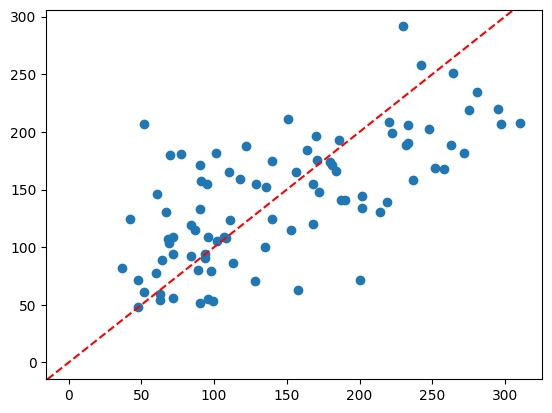

In [29]:
plt.scatter(y_test,y_pred)
plt.axline((0, 0), slope=1, color="red", linestyle="--")
plt.show()

In [31]:
# Diagnosing befoe changing the model
print("Train R2:", model.score(X_train, y_train))
print("Test R2:", model.score(X_test, y_test))

Train R2: 0.5279193863361498
Test R2: 0.4526027629719195


In [48]:
poly = PolynomialFeatures(degree = 2)


In [53]:
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [50]:
model_poly = LinearRegression()
model.fit(X_train_poly,y_train)
y_pred_poly = model.predict(X_test_poly)


In [51]:
print("model metrics")
print("R2 score", (r2_score(y_test,y_pred_poly)) )

model metrics
R2 score 0.4156399336408013


In [55]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_poly, y_train)

y_pred_ridge = ridge.predict(X_test_poly)

print("Ridge R2:", r2_score(y_test, y_pred_ridge))

Ridge R2: 0.41958396582030866
